# Section 3 on Google Colab: train and evaluate the washing-machine model

Training runs here, not on the laptop. The notebook only copies code and small data files, runs `scripts/run_section3.py`, and saves results back to Google Drive.

**Before running (once, on your Mac):**
1. Make a Drive folder `refit-nilm` with a sub-folder `minute`.
2. Upload the files from `data/processed/minute/*.parquet` into `refit-nilm/minute` (small files, about a few MB each).
3. Code: either push the repo to GitHub and set `GITHUB_URL` below, or zip the code (`zip -r refit-nilm-code.zip src scripts config.yaml`) and upload the zip to `refit-nilm` in Drive.

Run the cells top to bottom. No GPU is needed (LightGBM runs on the CPU; the default Colab runtime is fine).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
DRIVE_DIR = "/content/drive/MyDrive/refit-nilm"   # the Drive folder you made
GITHUB_URL = ""   # e.g. "https://github.com/<user>/<repo>.git"; leave empty to use refit-nilm-code.zip from Drive

In [3]:
import os, shutil
%cd /content
if os.path.exists("refit-nilm"):
    shutil.rmtree("refit-nilm")
if GITHUB_URL:
    !git clone {GITHUB_URL} refit-nilm
else:
    !unzip -q {DRIVE_DIR}/refit-nilm-v2.zip -d refit-nilm
%cd /content/refit-nilm
!ls

/content
/content/refit-nilm
config.yaml  scripts  src


In [4]:
!pip -q install pyyaml pyarrow
import lightgbm, pandas
print("lightgbm", lightgbm.__version__, "| pandas", pandas.__version__)

lightgbm 4.6.0 | pandas 2.2.3


In [5]:
os.makedirs("data/processed/minute", exist_ok=True)
!cp {DRIVE_DIR}/minute/*.parquet data/processed/minute/
!ls -la data/processed/minute

total 29268
drwxr-xr-x 2 root root    4096 Nov  6 14:45 .
drwxr-xr-x 3 root root    4096 Nov  6 14:45 ..
-rw------- 1 root root 7780774 Nov  6 14:45 house1.parquet
-rw------- 1 root root 7288665 Nov  6 14:45 house2.parquet
-rw------- 1 root root 6970605 Nov  6 14:45 house6.parquet
-rw------- 1 root root 7914521 Nov  6 14:45 house7.parquet


## Smoke test (a minute or less): few trees, only checks that everything runs

In [6]:
!python scripts/run_section3.py --quick --experiments loho --out outputs/quick

house 1: 920,091 minutes, valid 801,279
house 2: 889,078 minutes, valid 663,642
house 6: 831,480 minutes, valid 699,618
house 7: 882,970 minutes, valid 766,991
    fit lgbm_tweedie: 575,917 train rows, 14 s, best iteration 50
    fit lgbm_l2: 575,917 train rows, 9 s, best iteration 50
    metrics: 1 s | whole fold: 26 s
[loho] test house 1 done
    fit lgbm_tweedie: 624,822 train rows, 11 s, best iteration 50
    fit lgbm_l2: 624,822 train rows, 6 s, best iteration 50
    metrics: 0 s | whole fold: 20 s
[loho] test house 2 done
    fit lgbm_tweedie: 600,467 train rows, 12 s, best iteration 50
    fit lgbm_l2: 600,467 train rows, 9 s, best iteration 50
    metrics: 0 s | whole fold: 24 s
[loho] test house 6 done
    fit lgbm_tweedie: 584,193 train rows, 7 s, best iteration 31
    fit lgbm_l2: 584,193 train rows, 8 s, best iteration 50
    metrics: 0 s | whole fold: 18 s
[loho] test house 7 done

=== loho: mean over test houses ===
                 mae_w  mae_on_w  energy_error     f1  c

## Full run

In [7]:
!python scripts/run_section3.py --experiments loho,timesplit

house 1: 920,091 minutes, valid 801,279
house 2: 889,078 minutes, valid 663,642
house 6: 831,480 minutes, valid 699,618
house 7: 882,970 minutes, valid 766,991
    fit lgbm_tweedie: 575,917 train rows, 227 s, best iteration 2000
    fit lgbm_l2: 575,917 train rows, 38 s, best iteration 391
    metrics: 1 s | whole fold: 414 s
[loho] test house 1 done
    fit lgbm_tweedie: 624,822 train rows, 164 s, best iteration 1225
    fit lgbm_l2: 624,822 train rows, 129 s, best iteration 1626
    metrics: 0 s | whole fold: 443 s
[loho] test house 2 done
    fit lgbm_tweedie: 600,467 train rows, 222 s, best iteration 1998
    fit lgbm_l2: 600,467 train rows, 71 s, best iteration 870
    metrics: 0 s | whole fold: 445 s
[loho] test house 6 done
    fit lgbm_tweedie: 584,193 train rows, 220 s, best iteration 1998
    fit lgbm_l2: 584,193 train rows, 24 s, best iteration 260
    metrics: 1 s | whole fold: 392 s
[loho] test house 7 done

=== loho: mean over test houses ===
                 mae_w  mae_o

In [8]:
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
for exp in ("loho", "timesplit"):
    m = pd.read_csv(f"outputs/section3/metrics_{exp}.csv")
    print(exp)
    display(m)

loho


,experiment,test_house,model,n_minutes,mean_true_w,mae_w,mae_on_w,energy_error,precision,recall,f1,n_true_cycles,n_pred_cycles,cycle_recall,cycle_precision,cycle_energy_mae_wh,train_houses,val_mae_w,best_iteration
0,loho,1,always_off,801279,10.376427,10.376427,562.573634,-1.000000,0.000000,0.000000,0.000000,391,0,0.000000,NaN,338.168388,"[2, 6, 7]",NaN,NaN
1,loho,1,train_mean,801279,10.376427,30.521373,541.592771,1.022162,0.018386,1.000000,0.036107,391,405,1.000000,0.385185,324.262131,"[2, 6, 7]",NaN,NaN
2,loho,1,hourly_profile,801279,10.376427,30.155201,533.941998,1.014912,0.026657,0.662028,0.051251,391,1678,0.716113,0.134684,318.187997,"[2, 6, 7]",NaN,NaN
3,loho,1,lgbm_tweedie,801279,10.376427,10.945283,501.607265,-0.716695,0.358426,0.542968,0.431807,391,366,0.475703,0.524590,296.055312,"[2, 6, 7]",18.318342,2000.0
4,loho,1,lgbm_l2,801279,10.376427,15.388054,467.211724,-0.160185,0.163696,0.738664,0.268000,391,1078,0.877238,0.311688,273.087884,"[2, 6, 7]",24.445909,391.0
5,loho,2,always_off,663642,18.276301,18.276301,384.924525,-1.000000,0.000000,0.000000,0.000000,339,0,0.000000,NaN,588.227566,"[1, 6, 7]",NaN,NaN
6,loho,2,train_mean,663642,18.276301,34.530177,366.793268,-0.007936,0.000000,0.000000,0.000000,339,0,0.000000,NaN,558.739760,"[1, 6, 7]",NaN,NaN
7,loho,2,hourly_profile,663642,18.276301,33.947203,361.229532,-0.006454,0.075122,0.556586,0.132376,339,1170,0.746313,0.198291,545.367787,"[1, 6, 7]",NaN,NaN
8,loho,2,lgbm_tweedie,663642,18.276301,19.893150,370.731478,-0.821196,0.249903,0.123023,0.164879,339,147,0.144543,0.333333,556.195091,"[1, 6, 7]",13.329902,1225.0
9,loho,2,lgbm_l2,663642,18.276301,26.923864,332.807769,-0.195897,0.195749,0.320613,0.243084,339,635,0.463127,0.286614,472.168427,"[1, 6, 7]",15.700854,1626.0


timesplit


,experiment,test_house,model,n_minutes,mean_true_w,mae_w,mae_on_w,energy_error,precision,recall,f1,n_true_cycles,n_pred_cycles,cycle_recall,cycle_precision,cycle_energy_mae_wh,train_houses,val_mae_w,best_iteration
0,timesplit,1,always_off,234712,11.403474,11.403474,603.376101,-1.000000,0.000000,0.000000,0.000000,116,0,0.000000,NaN,378.856328,[1],NaN,NaN
1,timesplit,1,train_mean,234712,11.403474,20.268047,594.120963,-0.188393,0.000000,0.000000,0.000000,116,0,0.000000,NaN,372.525335,[1],NaN,NaN
2,timesplit,1,hourly_profile,234712,11.403474,19.854100,583.341360,-0.188099,0.047224,0.399096,0.084455,116,307,0.517241,0.146580,364.885278,[1],NaN,NaN
3,timesplit,1,lgbm_tweedie,234712,11.403474,9.042617,450.432681,-0.609176,0.694981,0.610169,0.649819,116,81,0.672414,0.962963,257.960178,[1],7.257615,448.0
4,timesplit,1,lgbm_l2,234712,11.403474,15.063567,355.953808,0.181967,0.169783,0.777627,0.278714,116,387,0.939655,0.281654,205.985278,[1],11.669456,107.0
5,timesplit,2,always_off,234025,19.589446,19.589446,416.623182,-1.000000,0.000000,0.000000,0.000000,123,0,0.000000,NaN,619.152310,[2],NaN,NaN
6,timesplit,2,train_mean,234025,19.589446,34.776802,399.663740,-0.134256,0.000000,0.000000,0.000000,123,0,0.000000,NaN,592.543451,[2],NaN,NaN
7,timesplit,2,hourly_profile,234025,19.589446,34.072296,393.639788,-0.138707,0.077965,0.514382,0.135407,123,610,0.772358,0.157377,578.835154,[2],NaN,NaN
8,timesplit,2,lgbm_tweedie,234025,19.589446,21.609205,351.427878,-0.517728,0.330332,0.542781,0.410710,123,226,0.772358,0.477876,482.125636,[2],18.117663,772.0
9,timesplit,2,lgbm_l2,234025,19.589446,36.006173,301.335789,0.528793,0.163118,0.533102,0.249802,123,430,0.756098,0.276744,368.475424,[2],23.613370,101.0


## Save results back to Drive

In [9]:
!mkdir -p {DRIVE_DIR}/outputs
!cp -r outputs/section3 {DRIVE_DIR}/outputs/
!ls -la {DRIVE_DIR}/outputs/section3

total 73987
drwx------ 2 root root     4096 Nov  6 15:28 .
drwx------ 3 root root     4096 Nov  6 15:28 ..
-rw------- 1 root root     3012 Nov  6 15:28 importance_loho.csv
-rw------- 1 root root     2816 Nov  6 15:28 importance_timesplit.csv
-rw------- 1 root root     4534 Nov  6 15:28 metrics_loho.csv
-rw------- 1 root root     4534 Nov  6 15:28 metrics_loho_partial.csv
-rw------- 1 root root     4383 Nov  6 15:28 metrics_timesplit.csv
-rw------- 1 root root     4383 Nov  6 15:28 metrics_timesplit_partial.csv
-rw------- 1 root root 58304340 Nov  6 15:28 predictions_loho.parquet
-rw------- 1 root root 17424429 Nov  6 15:28 predictions_timesplit.parquet


In [10]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("outputs/section3")

importance_files = sorted(
    OUTPUT_DIR.glob("importance_*.csv")
)

print("Feature importance files found:", len(importance_files))

if not importance_files:
    print("No feature importance CSV files found.")
else:
    for file in importance_files:

        print("\n" + "=" * 65)
        print("FILE:", file.name)
        print("=" * 65)

        df = pd.read_csv(file)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        # Identify importance column
        importance_col = next(
            (
                col for col in [
                    "gain",
                    "importance_gain",
                    "total_gain",
                    "importance",
                    "split",
                    "importance_split"
                ]
                if col in df.columns
            ),
            None
        )

        if importance_col is not None:

            display(
                df.sort_values(
                    importance_col,
                    ascending=False
                ).head(15)
            )

        else:
            display(df.head(15))

Feature importance files found: 2

FILE: importance_loho.csv
Shape: (144, 4)
Columns: ['Unnamed: 0', 'lgbm_tweedie', 'lgbm_l2', 'test_house']


,Unnamed: 0,lgbm_tweedie,lgbm_l2,test_house
0,agg,822,248,1
1,agg_t-30,2699,655,1
2,agg_t-20,2109,573,1
3,agg_t-15,1967,491,1
4,agg_t-10,1958,495,1
5,agg_t-5,1497,307,1
6,agg_t-3,1300,244,1
7,agg_t-2,1121,209,1
8,agg_t-1,896,171,1
9,agg_t+1,984,198,1



FILE: importance_timesplit.csv
Shape: (144, 4)
Columns: ['Unnamed: 0', 'lgbm_tweedie', 'lgbm_l2', 'test_house']


,Unnamed: 0,lgbm_tweedie,lgbm_l2,test_house
0,agg,223,79,1
1,agg_t-30,502,116,1
2,agg_t-20,404,84,1
3,agg_t-15,329,47,1
4,agg_t-10,297,66,1
5,agg_t-5,289,75,1
6,agg_t-3,258,74,1
7,agg_t-2,201,52,1
8,agg_t-1,228,56,1
9,agg_t+1,268,93,1


In [11]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("outputs/section3")

importance_files = {
    "LOHO": OUTPUT_DIR / "importance_loho.csv",
    "TIMESPLIT": OUTPUT_DIR / "importance_timesplit.csv"
}

models = ["lgbm_tweedie", "lgbm_l2"]

for experiment, file in importance_files.items():

    print("\n" + "=" * 75)
    print(f"EXPERIMENT: {experiment}")
    print("=" * 75)

    df = pd.read_csv(file)

    # Identify the feature-name column
    feature_col = (
        "Unnamed: 0"
        if "Unnamed: 0" in df.columns
        else df.columns[0]
    )

    # Check available test houses
    print("Test houses:", sorted(df["test_house"].unique()))

    for house in sorted(df["test_house"].unique()):

        house_df = df[df["test_house"] == house].copy()

        print(f"\n{'-' * 60}")
        print(f"TEST HOUSE: {house}")
        print(f"{'-' * 60}")

        for model in models:

            top_features = (
                house_df[[feature_col, model]]
                .sort_values(model, ascending=False)
                .head(10)
                .rename(columns={
                    feature_col: "Feature",
                    model: "Importance_Score"
                })
            )

            print(f"\nTop 10 features — {model}")
            display(top_features.reset_index(drop=True))


EXPERIMENT: LOHO
Test houses: [np.int64(1), np.int64(2), np.int64(6), np.int64(7)]

------------------------------------------------------------
TEST HOUSE: 1
------------------------------------------------------------

Top 10 features — lgbm_tweedie


,Feature,Importance_Score
0,roll61_max,3127
1,agg_t-30,2699
2,roll61_std,2653
3,roll61_min,2484
4,roll5_std,2165
5,agg_t+30,2130
6,agg_t-20,2109
7,roll31_max,2099
8,baseload,2062
9,roll61_mean,2022



Top 10 features — lgbm_l2


,Feature,Importance_Score
0,agg_t-30,655
1,agg_t+30,575
2,agg_t-20,573
3,agg_t+20,531
4,agg_t-10,495
5,agg_t-15,491
6,agg_t+15,462
7,agg_minus_baseload,425
8,roll15_min,417
9,roll5_std,407



------------------------------------------------------------
TEST HOUSE: 2
------------------------------------------------------------

Top 10 features — lgbm_tweedie


,Feature,Importance_Score
0,roll61_max,1822
1,roll61_std,1775
2,roll61_min,1616
3,roll5_std,1487
4,agg_t-30,1455
5,agg_t+30,1347
6,roll61_mean,1280
7,roll15_std,1216
8,roll31_min,1197
9,agg_t-20,1190


... (22 outputs left out)


------------------------------------------------------------
TEST HOUSE: 7
------------------------------------------------------------

Top 10 features — lgbm_tweedie


,Feature,Importance_Score
0,roll61_max,1470
1,roll61_min,1290
2,agg_t-30,1158
3,roll61_std,1114
4,agg_t+30,1012
5,roll31_max,987
6,roll5_std,965
7,roll31_min,959
8,baseload,942
9,agg_t-20,936



Top 10 features — lgbm_l2


,Feature,Importance_Score
0,agg_t-30,509
1,roll15_min,441
2,agg_t+30,433
3,agg_t-20,421
4,roll61_std,382
5,agg_t-15,381
6,agg_t+20,359
7,agg_t-10,352
8,roll61_min,347
9,diff1,340


In [12]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("outputs/section3")

prediction_files = [
    OUTPUT_DIR / "predictions_loho.parquet",
    OUTPUT_DIR / "predictions_timesplit.parquet"
]

for file in prediction_files:

    print("\n" + "=" * 65)
    print("FILE:", file.name)
    print("=" * 65)

    if not file.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_parquet(file)

    print("Shape:", df.shape)
    print("Index type:", type(df.index))
    print("Index name:", df.index.name)
    print("Index columns:", df.index.names)
    print("Columns:", df.columns.tolist())

    display(df.head(5))

    if "test_house" in df.columns:
        print("\nRows per test house:")
        display(df["test_house"].value_counts().sort_index())


FILE: predictions_loho.parquet
Shape: (3523619, 8)
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Index name: time
Index columns: ['time']
Columns: ['y_true', 'valid', 'pred_always_off', 'pred_train_mean', 'pred_hourly_profile', 'pred_lgbm_tweedie', 'pred_lgbm_l2', 'house']


,y_true,valid,pred_always_off,pred_train_mean,pred_hourly_profile,pred_lgbm_tweedie,pred_lgbm_l2,house
time,,,,,,,,
2013-10-09 13:06:00,0.0,True,0.0,20.982813,50.64636,3.894676,6.463065,1
2013-10-09 13:07:00,0.0,True,0.0,20.982813,50.64636,23.864094,4.421056,1
2013-10-09 13:08:00,0.0,True,0.0,20.982813,50.64636,97.077112,26.397898,1
2013-10-09 13:09:00,0.0,True,0.0,20.982813,50.64636,78.692582,46.647187,1
2013-10-09 13:10:00,0.0,True,0.0,20.982813,50.64636,125.059981,69.648671,1



FILE: predictions_timesplit.parquet
Shape: (1057085, 8)
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Index name: time
Index columns: ['time']
Columns: ['y_true', 'valid', 'pred_always_off', 'pred_train_mean', 'pred_hourly_profile', 'pred_lgbm_tweedie', 'pred_lgbm_l2', 'house']


,y_true,valid,pred_always_off,pred_train_mean,pred_hourly_profile,pred_lgbm_tweedie,pred_lgbm_l2,house
time,,,,,,,,
2014-12-30 19:30:00,0.0,True,0.0,9.255138,0.0,0.247432,33.760649,1
2014-12-30 19:31:00,0.0,True,0.0,9.255138,0.0,0.224901,8.978175,1
2014-12-30 19:32:00,0.0,True,0.0,9.255138,0.0,0.092922,29.851559,1
2014-12-30 19:33:00,0.0,True,0.0,9.255138,0.0,0.245237,35.576927,1
2014-12-30 19:34:00,0.0,True,0.0,9.255138,0.0,0.189827,9.122158,1


## Step E1: Prediction vs Ground Truth Analysis

The saved LOHO predictions are compared against actual
washing-machine power readings for representative test
households.

LightGBM Tweedie and LightGBM L2 predictions are compared
to understand how accurately the models reconstruct
appliance-level power consumption from aggregate household
electricity readings.

House 7 represents a relatively stronger-performing test
household, while House 2 represents a more challenging
cross-house generalization case.

Only valid evaluation minutes are displayed. Missing or
invalid observations are retained as gaps rather than
being treated as zero consumption.

Prediction data shape: (3523619, 8)
Households: [np.int64(1), np.int64(2), np.int64(6), np.int64(7)]

HOUSE 7
Window start: 2014-07-26 13:55:00
Window end: 2014-07-26 19:54:00
Valid active minutes: 313
Valid evaluation minutes: 360


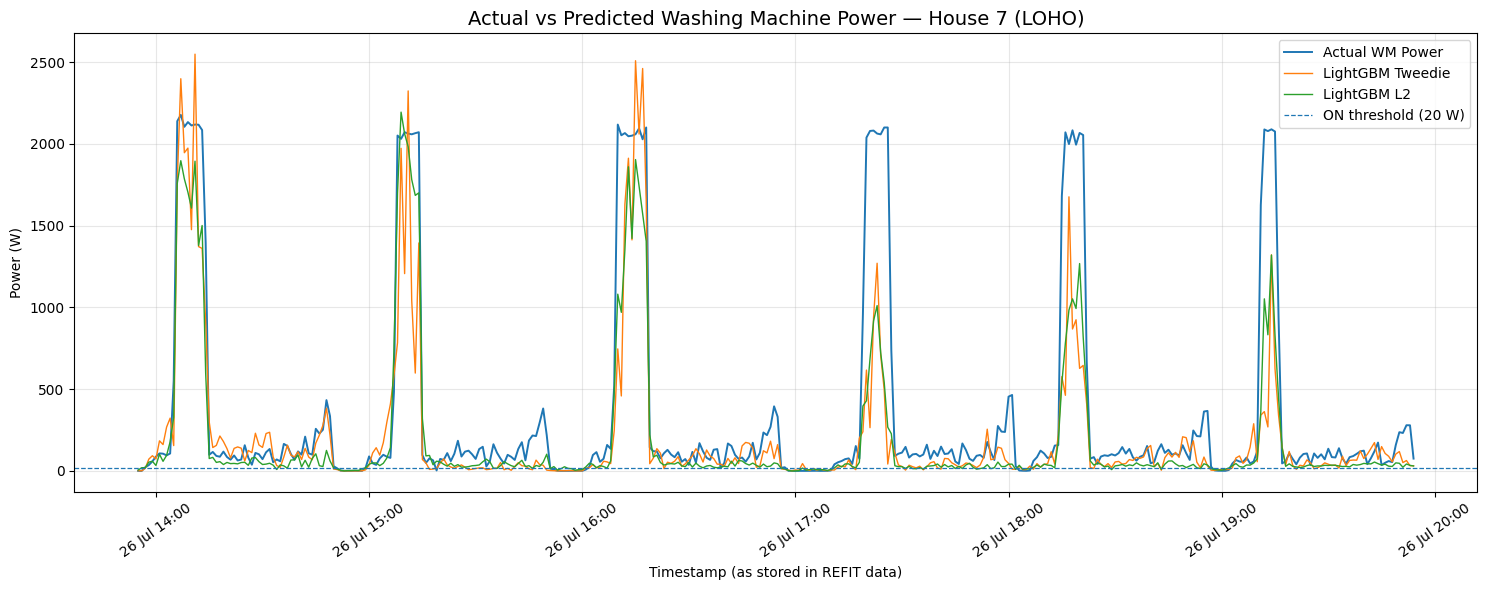

Saved: outputs/section3/figures/prediction_vs_actual_loho_house7.png

HOUSE 2
Window start: 2015-03-04 14:10:00
Window end: 2015-03-04 20:09:00
Valid active minutes: 301
Valid evaluation minutes: 360


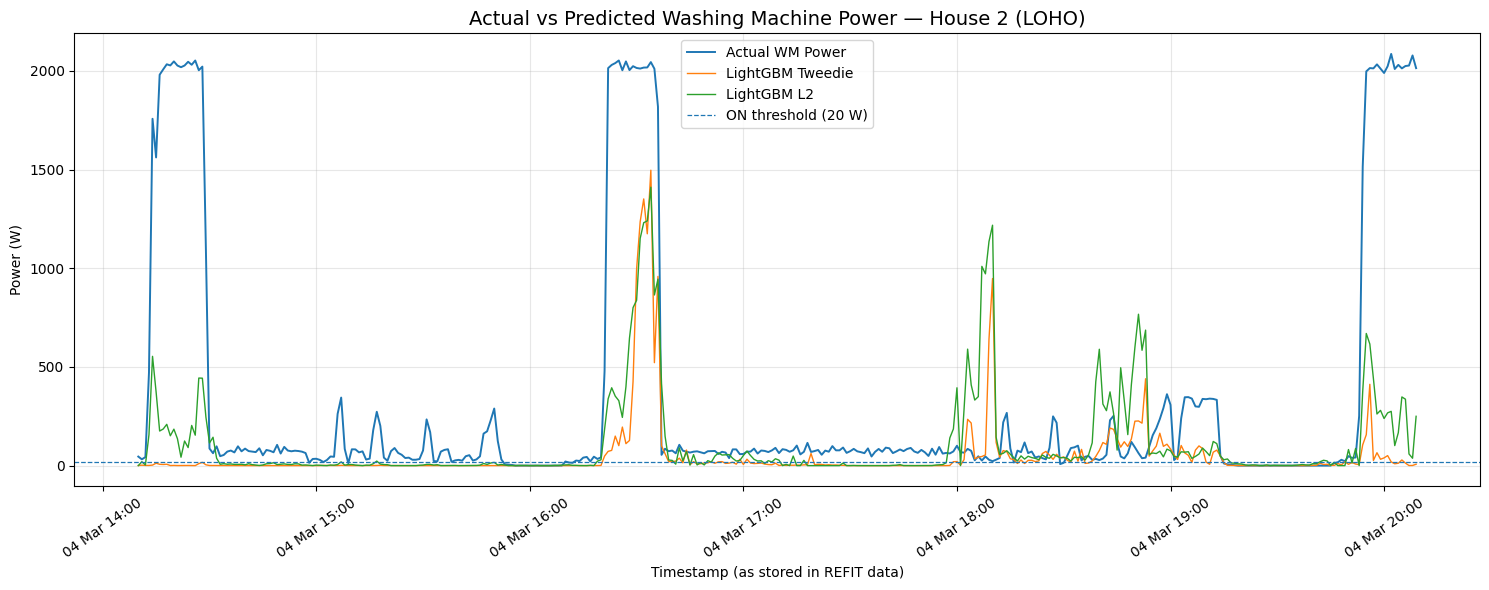

Saved: outputs/section3/figures/prediction_vs_actual_loho_house2.png

Prediction visualization completed.


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import matplotlib.dates as mdates

# ---------------------------------------------
# 1. Load LOHO predictions
# ---------------------------------------------

OUTPUT_DIR = Path("outputs/section3")
FIGURE_DIR = OUTPUT_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

predictions = pd.read_parquet(
    OUTPUT_DIR / "predictions_loho.parquet"
)

predictions = predictions.sort_index()

print("Prediction data shape:", predictions.shape)
print("Households:", sorted(predictions["house"].unique()))


# ---------------------------------------------
# 2. Select a representative active window
# ---------------------------------------------

def select_active_window(df, window_minutes=360):

    df = df.sort_index().copy()

    # Split the data wherever timestamps are not
    # exactly one minute apart.
    time_diff = df.index.to_series().diff()

    block_id = (
        time_diff.ne(pd.Timedelta(minutes=1))
        .cumsum()
        .to_numpy()
    )

    best_window = None
    best_score = -1

    for _, block in df.groupby(block_id, sort=False):

        if len(block) < window_minutes:
            continue

        valid = (
            block["valid"].fillna(False).astype(bool)
            & block["y_true"].notna()
        )

        active = (
            valid & (block["y_true"] > 20)
        ).astype(int)

        rolling_active = active.rolling(
            window=window_minutes,
            min_periods=window_minutes
        ).sum()

        # IMPORTANT FIX: Ignore initial NaN positions
        scores = rolling_active.to_numpy(dtype=float)

        finite_positions = np.flatnonzero(
            np.isfinite(scores)
        )

        if len(finite_positions) == 0:
            continue

        best_position = finite_positions[
            np.argmax(scores[finite_positions])
        ]

        score = float(scores[best_position])

        start_position = (
            best_position - window_minutes + 1
        )

        candidate = block.iloc[
            start_position:best_position + 1
        ]

        if len(candidate) != window_minutes:
            continue

        if score > best_score:
            best_score = score
            best_window = candidate.copy()

    if best_window is None:
        raise ValueError(
            "No continuous six-hour timestamp block found. "
            "Inspect the longest continuous block."
        )

    return best_window, best_score


# ---------------------------------------------
# 3. Generate plots for House 7 and House 2
# ---------------------------------------------

selected_houses = [7, 2]

for house_no in selected_houses:

    house_df = predictions[
        predictions["house"] == house_no
    ].copy()

    print("\n" + "=" * 60)
    print(f"HOUSE {house_no}")
    print("=" * 60)

    window, active_minutes = select_active_window(
        house_df,
        window_minutes=360
    )

    # Mask invalid evaluation points
    valid = (
        window["valid"].fillna(False).astype(bool)
        & window["y_true"].notna()
    )

    actual = window["y_true"].where(valid)

    tweedie = window["pred_lgbm_tweedie"].where(valid)
    l2 = window["pred_lgbm_l2"].where(valid)

    print("Window start:", window.index.min())
    print("Window end:", window.index.max())
    print("Valid active minutes:", int(active_minutes))
    print("Valid evaluation minutes:", int(valid.sum()))

    # -----------------------------------------
    # 4. Plot
    # -----------------------------------------

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        window.index,
        actual,
        label="Actual WM Power",
        linewidth=1.4
    )

    ax.plot(
        window.index,
        tweedie,
        label="LightGBM Tweedie",
        linewidth=1
    )

    ax.plot(
        window.index,
        l2,
        label="LightGBM L2",
        linewidth=1
    )

    ax.axhline(
        20,
        linestyle="--",
        linewidth=0.9,
        label="ON threshold (20 W)"
    )

    ax.set_title(
        f"Actual vs Predicted Washing Machine Power — "
        f"House {house_no} (LOHO)",
        fontsize=14
    )

    ax.set_xlabel(
        "Timestamp (as stored in REFIT data)"
    )

    ax.set_ylabel("Power (W)")

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d %b %H:%M")
    )

    plt.xticks(rotation=35)

    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    filename = (
        f"prediction_vs_actual_loho_house{house_no}.png"
    )

    plt.savefig(
        FIGURE_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Saved:", FIGURE_DIR / filename)

print("\nPrediction visualization completed.")

### Figure 8. Actual vs Predicted Washing Machine Power — House 7 (LOHO)

*Figure 8. Comparison of actual washing-machine power consumption with LightGBM Tweedie and LightGBM L2 predictions for House 7.*

**Interpretation:**

House 7 represents a relatively stronger-performing household
in the leave-one-house-out evaluation.

The Tweedie model captures several prominent high-power
activation events, although some actual peaks are underestimated.
The L2 model also identifies several activation periods but
shows differences in predicted magnitude and event alignment.

The results indicate that the model can identify a substantial
proportion of washing-machine activity in this household,
although exact power reconstruction remains imperfect.

### Figure 9. Actual vs Predicted Washing Machine Power — House 2 (LOHO)

*Figure 9. Comparison of actual washing-machine power consumption with LightGBM Tweedie and LightGBM L2 predictions for House 2.*

**Interpretation:**

House 2 represents a more challenging household for
cross-house generalization.

The Tweedie model underestimates several prominent
washing-machine activation events, while the L2 model
also exhibits mismatches between actual and predicted
power consumption.

The low cycle recall and F1 score indicate that the
models struggle to identify washing-machine activity
when evaluated on this unseen household.

This highlights the variability of appliance behaviour
across households and the limitations of transferring
a model trained on other homes.

Cross-house model comparison

CROSS-HOUSE MODEL SUMMARY


,experiment,model,mae_w,mae_on_w,energy_error,f1,cycle_recall,cycle_precision
0,loho,always_off,18.447,443.348,-1.000,0.000,0.000,NaN
1,loho,hourly_profile,34.518,418.269,0.582,0.105,0.711,0.200
2,loho,lgbm_l2,23.989,322.968,0.012,0.332,0.824,0.307
3,loho,lgbm_tweedie,17.973,362.787,-0.595,0.414,0.592,0.513
4,loho,train_mean,35.049,425.333,0.584,0.018,0.500,0.366
5,timesplit,always_off,20.668,475.230,-1.000,0.000,0.000,NaN
6,timesplit,hourly_profile,33.720,446.929,-0.143,0.152,0.713,0.236
7,timesplit,lgbm_l2,23.059,264.428,0.203,0.371,0.924,0.348
8,timesplit,lgbm_tweedie,16.576,333.814,-0.489,0.592,0.827,0.750
9,timesplit,train_mean,35.373,458.334,-0.146,0.042,0.250,0.857


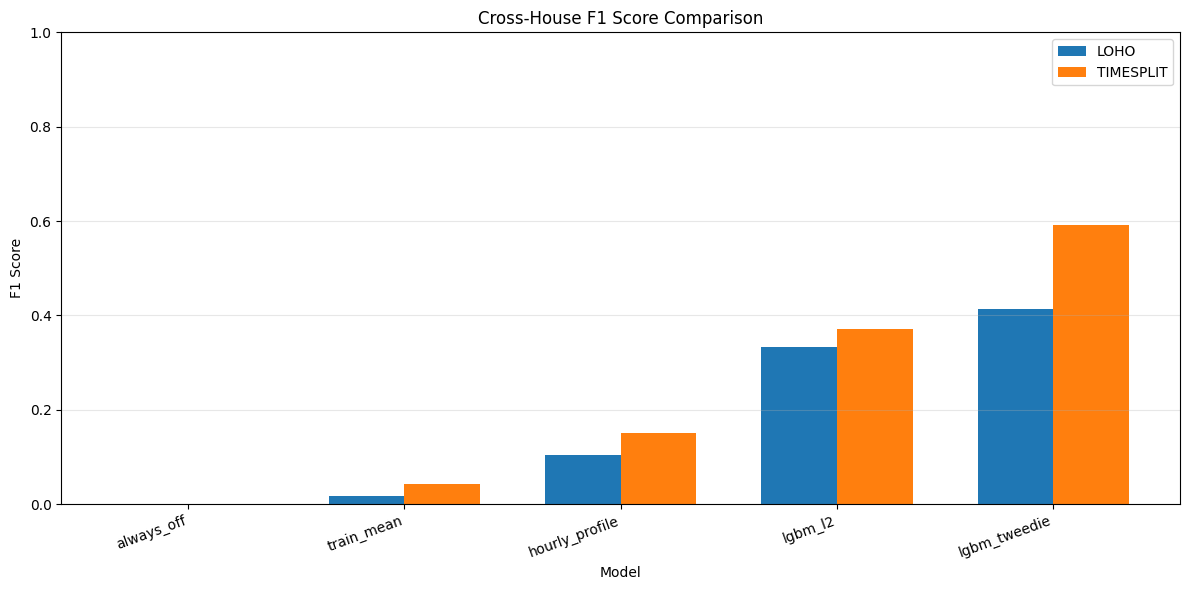

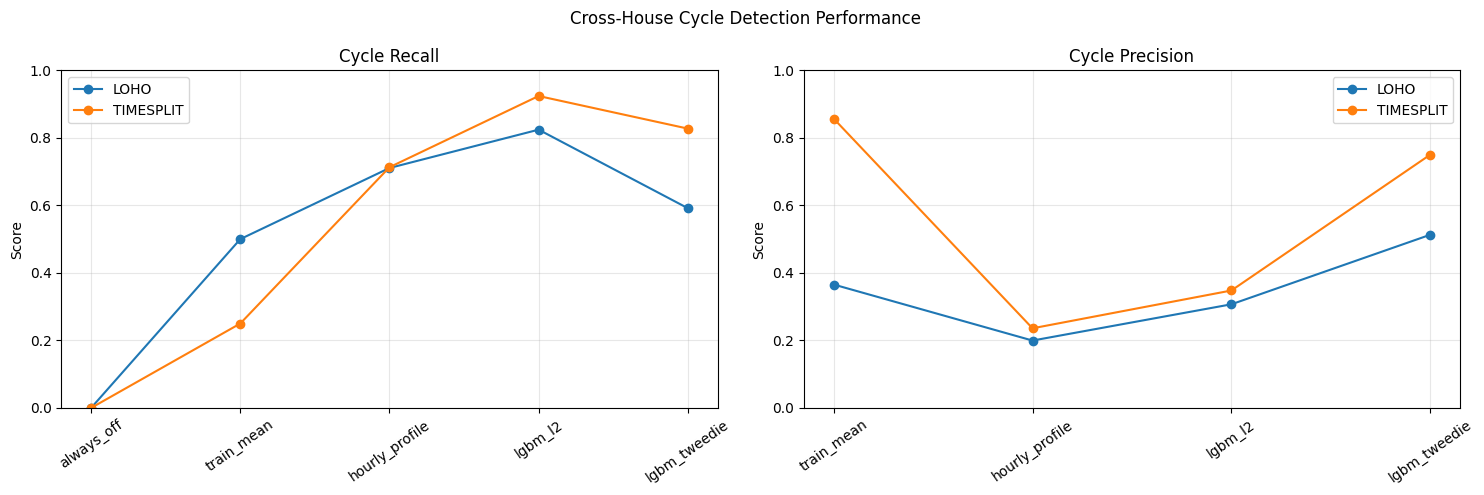

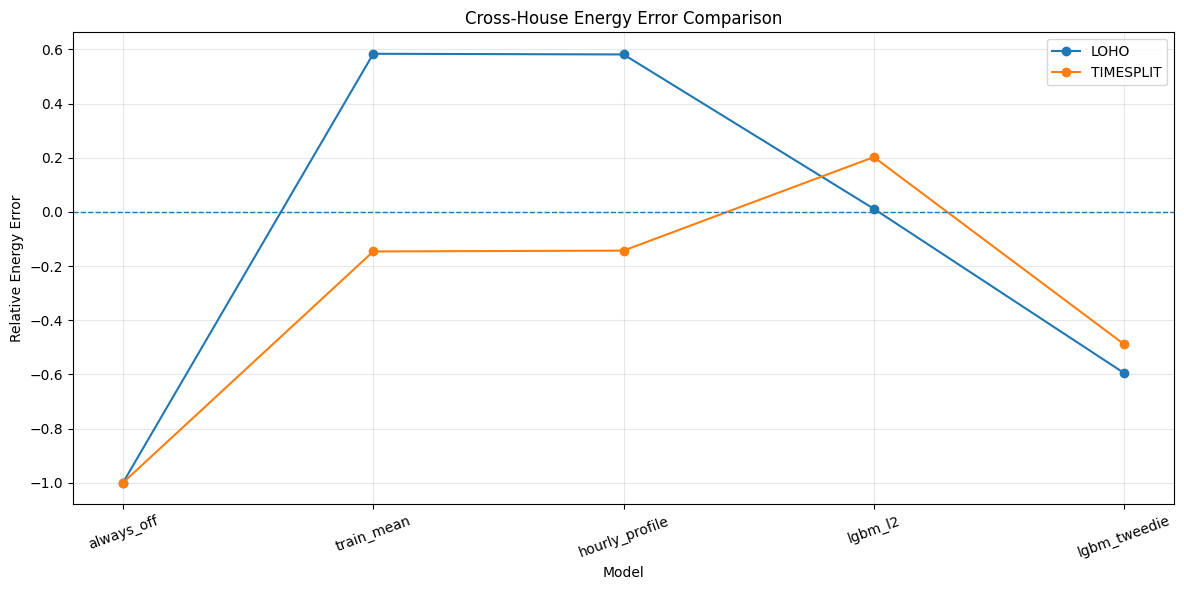


All cross-house comparison figures saved.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs/section3")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load saved evaluation metrics
loho = pd.read_csv(OUTPUT_DIR / "metrics_loho.csv")
timesplit = pd.read_csv(OUTPUT_DIR / "metrics_timesplit.csv")

metrics = pd.concat(
    [loho, timesplit],
    ignore_index=True
)

models = [
    "always_off",
    "train_mean",
    "hourly_profile",
    "lgbm_l2",
    "lgbm_tweedie"
]

experiments = ["loho", "timesplit"]

# ---------------------------------------
# 1. Cross-house average summary
# ---------------------------------------

summary_metrics = (
    metrics.groupby(["experiment", "model"])
    [[
        "mae_w",
        "mae_on_w",
        "energy_error",
        "f1",
        "cycle_recall",
        "cycle_precision"
    ]]
    .mean()
    .reset_index()
)

summary_metrics.to_csv(
    OUTPUT_DIR / "cross_house_metrics_summary.csv",
    index=False
)

print("CROSS-HOUSE MODEL SUMMARY")
display(summary_metrics.round(3))

# Save house-wise comparison
metrics.to_csv(
    OUTPUT_DIR / "cross_house_metrics_by_house.csv",
    index=False
)

# ---------------------------------------
# 2. Plot F1 comparison
# ---------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(models))
width = 0.35

for i, experiment in enumerate(experiments):

    values = (
        summary_metrics[
            summary_metrics["experiment"] == experiment
        ]
        .set_index("model")
        .reindex(models)["f1"]
    )

    ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=experiment.upper()
    )

ax.set_title("Cross-House F1 Score Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("F1 Score")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "cross_house_f1_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ---------------------------------------
# 3. Plot cycle recall and precision
# ---------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cycle_metrics = [
    ("cycle_recall", "Cycle Recall"),
    ("cycle_precision", "Cycle Precision")
]

for ax, (metric, title) in zip(axes, cycle_metrics):

    for experiment in experiments:

        subset = (
            summary_metrics[
                summary_metrics["experiment"] == experiment
            ]
            .set_index("model")
            .reindex(models)
        )

        ax.plot(
            models,
            subset[metric],
            marker="o",
            label=experiment.upper()
        )

    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Cross-House Cycle Detection Performance")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "cross_house_cycle_metrics.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ---------------------------------------
# 4. Plot energy error
# ---------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

for experiment in experiments:

    subset = (
        summary_metrics[
            summary_metrics["experiment"] == experiment
        ]
        .set_index("model")
        .reindex(models)
    )

    ax.plot(
        models,
        subset["energy_error"],
        marker="o",
        label=experiment.upper()
    )

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title("Cross-House Energy Error Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Relative Energy Error")
ax.tick_params(axis="x", rotation=20)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "cross_house_energy_error.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nAll cross-house comparison figures saved.")

In [16]:
from pathlib import Path

!mkdir -p "{DRIVE_DIR}/outputs/section3"
!cp -r outputs/section3/. "{DRIVE_DIR}/outputs/section3/"

print("Final Section 3 output files:")
!find "{DRIVE_DIR}/outputs/section3" -maxdepth 2 -type f

Final Section 3 output files:
/content/drive/MyDrive/refit-nilm/outputs/section3/metrics_loho_partial.csv
/content/drive/MyDrive/refit-nilm/outputs/section3/metrics_loho.csv
/content/drive/MyDrive/refit-nilm/outputs/section3/predictions_loho.parquet
/content/drive/MyDrive/refit-nilm/outputs/section3/importance_loho.csv
/content/drive/MyDrive/refit-nilm/outputs/section3/metrics_timesplit_partial.csv
/content/drive/MyDrive/refit-nilm/outputs/section3/metrics_timesplit.csv
/content/drive/MyDrive/refit-nilm/outputs/section3/predictions_timesplit.parquet
/content/drive/MyDrive/refit-nilm/outputs/section3/importance_timesplit.csv
/content/drive/MyDrive/refit-nilm/outputs/section3/figures/prediction_vs_actual_loho_house7.png
/content/drive/MyDrive/refit-nilm/outputs/section3/figures/prediction_vs_actual_loho_house2.png
/content/drive/MyDrive/refit-nilm/outputs/section3/figures/cross_house_f1_comparison.png
/content/drive/MyDrive/refit-nilm/outputs/section3/figures/cross_house_cycle_metrics.pn